In [1]:
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send
from langchain_groq import ChatGroq
from langchain_core.messages import SystemMessage, HumanMessage
from langchain_tavily import TavilySearch
from pydantic import BaseModel, Field
from typing import TypedDict, Annotated, List, Literal, Optional
from operator import add
from dotenv import load_dotenv
from pathlib import Path
from collections import deque
from threading import Lock
from time import monotonic, sleep
import json

TPM_BUDGET = 7600
# This rolling ledger covers only requests sent through this notebook process.
_tpm_reservations = deque()
_tpm_lock = Lock()

def _invoke_with_tpm_budget(runnable, messages, max_output_tokens: int, schema=None):
    schema_bytes = 0
    if schema is not None:
        schema_bytes = len(json.dumps(schema.model_json_schema(), separators=(",", ":")).encode("utf-8"))

    prompt_bytes = sum(len(message.content.encode("utf-8")) for message in messages)
    # Reserve one token per UTF-8 byte plus framing overhead; this intentionally overestimates normal prose.
    prompt_bound = prompt_bytes + schema_bytes + 64 * len(messages) + 256
    reservation = prompt_bound + max_output_tokens
    if reservation > TPM_BUDGET:
        raise ValueError(f"Request budget ({reservation}) exceeds the {TPM_BUDGET}-token workflow limit.")

    while True:
        with _tpm_lock:
            now = monotonic()
            while _tpm_reservations and now - _tpm_reservations[0][0] >= 60:
                _tpm_reservations.popleft()

            reserved = sum(tokens for _, tokens in _tpm_reservations)
            if reserved + reservation <= TPM_BUDGET:
                _tpm_reservations.append((now, reservation))
                break

            wait_seconds = 60 - (now - _tpm_reservations[0][0]) + 0.1

        sleep(max(wait_seconds, 0.1))

    return runnable.invoke(messages)

In [2]:
load_dotenv()

llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0,
    max_retries=0,
)

In [20]:
class Task(BaseModel):
    id: int
    title: str = Field(max_length=80)

    goal: str = Field(
        ...,
        max_length=180,
        description="One sentence describing what the reader should be able to do/understand after this section.",
    )
    bullets: List[Annotated[str, Field(max_length=180)]] = Field(
        ...,
        min_length=3,
        max_length=5,
        description="3-5 concise, concrete, non-overlapping subpoints to cover in this section; prefer 3 and keep each under 160 characters.",
    )
    target_words: int = Field(135, ge=120, le=150, description="Target word count for this section (120–150).")

    tags: List[str] = Field(default_factory=list, max_length=2)
    requires_research: bool = False
    requires_citations: bool = False
    requires_code: bool = False

class Plan(BaseModel):
    blog_title: str = Field(max_length=100)
    audience: str = Field(max_length=80)
    tone: str = Field(max_length=40)
    blog_kind: Literal["explainer", "tutorial", "news_roundup", "comparison", "system_design"] = "explainer"
    constraints: List[str] = Field(default_factory=list, max_length=2)
    tasks: List[Task] = Field(min_length=5, max_length=5)

class EvidenceItem(BaseModel):
    title: str
    url: str
    published_at: Optional[str] = None  # keep if Tavily provides; DO NOT rely on it
    snippet: Optional[str] = None
    source: Optional[str] = None

class RouterDecision(BaseModel):
    needs_research: bool
    mode: Literal["closed_book", "hybrid", "open_book"]
    queries: List[str] = Field(default_factory=list, max_length=3)

class EvidencePack(BaseModel):
    evidence: List[EvidenceItem] = Field(default_factory=list)

In [4]:
class ImageSpec(BaseModel):
    section_id: int = Field(ge=1, le=5)
    placement: Literal["after_heading", "mid_section", "end_section"]
    alt: str = Field(min_length=1, max_length=120)
    caption: str = Field(default="", max_length=180)
    prompt: str = Field(min_length=1, max_length=700)

class GlobalImagePlan(BaseModel):
    images: List[ImageSpec] = Field(default_factory=list, max_length=1)

In [5]:
class BlogState(TypedDict):
    topic: str

    # routing / research
    mode: str
    needs_research: bool
    queries: List[str]
    evidence: List[EvidenceItem]
    plan: Optional[Plan]

    # workers
    sections: Annotated[List[tuple[int, str]], add]  # (task_id, section_md)
    final: str

In [6]:
#router node
ROUTER_SYSTEM = """You are a routing module for a technical blog planner. Decide whether web research is needed before planning.

Modes:
- closed_book: needs_research=false for evergreen topics whose correctness does not depend on recent facts (concepts/fundamentals).
- hybrid: needs_research=true for mostly evergreen topics needing current examples, tools, or models.
- open_book: needs_research=true for volatile topics (weekly roundups, latest news, rankings, pricing, policies/regulations).

If needs_research=true, output at most 3 specific, scoped queries; include an explicit requested time period when relevant.
"""

def router_node(state: BlogState) -> dict:
    
    topic = state["topic"]
    messages = [
            SystemMessage(content=ROUTER_SYSTEM),
            HumanMessage(content=f"Topic: {topic}"),
        ]
    decision = _invoke_with_tpm_budget(
        llm.bind(max_tokens=128).with_structured_output(RouterDecision),
        messages,
        max_output_tokens=128,
        schema=RouterDecision,
    )

    return {
        "needs_research": decision.needs_research,
        "mode": decision.mode,
        "queries": decision.queries,
    }


In [7]:
# Researcher node
def _tavily_search(query: str, max_results: int = 5) -> List[dict]:
    
    tool = TavilySearch(max_results=max_results)
    results = tool.invoke({"query": query})['results']

    normalized: List[dict] = []
    for r in results or []:
        normalized.append(
            {
                "title": r.get("title") or "",
                "url": r.get("url") or "",
                "snippet": r.get("content") or r.get("snippet") or "",
                # "published_at": r.get("published_date") or r.get("published_at"),
                # "source": r.get("source"),
            }
        )
    return normalized

def research_node(state: BlogState) -> dict:

    # Bound search fanout to keep the evidence payload compact.
    queries = (state.get("queries", []) or [])[:3]
    max_results = 2

    raw_results: List[dict] = []

    for q in queries:
        raw_results.extend(_tavily_search(q, max_results=max_results))

    if not raw_results:
        return {"evidence": []}

    # Search results already have the fields required by EvidenceItem; avoid a
    # second model call to reformat them as structured output.
    dedup: dict[str, EvidenceItem] = {}
    for result in raw_results:
        url = result.get("url")
        if not url:
            continue

        dedup[url] = EvidenceItem(
            title=(result.get("title") or url)[:120],
            url=url,
            snippet=(result.get("snippet") or "")[:240] or None,
        )

    return {"evidence": list(dedup.values())[:4]}

In [19]:
# 5) Orchestrator (Plan)
# -----------------------------
ORCH_SYSTEM = """Create a concise, developer-oriented technical blog plan.
Return exactly 5 sections. Each needs one short goal, exactly 3 distinct actionable bullets (prefer 3), and 120–150 target words. Set requires_code=True for one useful example; cover relevant failure modes or performance/debugging.
Use evergreen knowledge in closed_book mode. In hybrid mode, use evidence only for current claims and set citation flags accordingly. In open_book mode, create a news roundup and include only evidence-supported events; disclose insufficient sources.
Keep titles, goals, bullets, and constraints brief. Match the Plan schema exactly.
"""

def orchestrator_node(state: BlogState) -> dict:
    planner = llm.bind(max_tokens=800).with_structured_output(Plan)

    evidence = state.get("evidence", [])
    mode = state.get("mode", "closed_book")

    messages = [
            SystemMessage(content=ORCH_SYSTEM),
            HumanMessage(
                content=(
                    f"Topic: {state['topic']}\n"
                    f"Mode: {mode}\n\n"
                    f"Evidence (ONLY use for fresh claims; may be empty):\n"
                    f"{json.dumps([{'title': e.title, 'url': e.url, 'snippet': (e.snippet or '')[:160]} for e in evidence[:3]], ensure_ascii=True)}"
                )
            ),
        ]
    plan = _invoke_with_tpm_budget(
        planner,
        messages,
        max_output_tokens=800,
        schema=Plan,
    )

    return {"plan": plan}

In [9]:
# 6) Fanout
# -----------------------------
def fanout(state: BlogState):
    return [
        Send(
            "worker",
            {
                "tasks": [task.model_dump() for task in state["plan"].tasks],
                "topic": state["topic"],
                "mode": state["mode"],
                "plan": state["plan"].model_dump(),
                "evidence": [e.model_dump() for e in state.get("evidence", [])[:4]],
            },
        )
    ]

In [10]:
# -----------------------------
# 7) Worker (write one section)
# -----------------------------
WORKER_SYSTEM = """Write all five planned sections as concise Markdown, in order, at 120–150 words each.
Cover each section's goal and all of its bullet points, matching the plan. Start each section with its ## title; output no H1 or commentary.
For open_book news, include only claims supported by the supplied URLs and cite them inline. In hybrid mode, cite evidence-backed current claims. Include a short, correct code example when a task requires_code. Avoid repetition and fluff.
"""

def worker_node(payload: dict) -> dict:
    tasks = [Task(**task) for task in payload["tasks"]]
    plan = Plan(**payload["plan"])
    evidence = [EvidenceItem(**e) for e in payload.get("evidence", [])[:4]]
    topic = payload["topic"]
    mode = payload.get("mode", "closed_book")

    task_text = "\n\n".join(
        f"{task.id}. {task.title} ({task.target_words} words; citations={task.requires_citations}; code={task.requires_code})\n"
        f"Goal: {task.goal}\n- " + "\n- ".join(task.bullets)
        for task in tasks
    )
    evidence_text = "\n".join(
        f"- {item.title} | {item.url} | {(item.snippet or '')[:160]}"
        for item in evidence
    )

    messages = [
            SystemMessage(content=WORKER_SYSTEM),
            HumanMessage(
                content=(
                    f"Title: {plan.blog_title}\nTopic: {topic}\nAudience: {plan.audience}\n"
                    f"Mode: {mode}; blog kind: {plan.blog_kind}\n"
                    f"Sections:\n{task_text}\n\nEvidence (cite only these URLs):\n{evidence_text}"
                )
            ),
        ]
    response = _invoke_with_tpm_budget(
        llm.bind(max_tokens=1900),
        messages,
        max_output_tokens=1900,
    )
    sections_md = response.content.strip()

    return {"sections": [(0, sections_md)]}

In [11]:
# -----------------------------
# 8) Reducer subgraph (merge + plan + generate/render)
# -----------------------------
import base64
import os
import re
import warnings

CLOUDFLARE_IMAGE_MODEL = "@cf/black-forest-labs/flux-1-schnell"
CLOUDFLARE_IMAGE_STEPS = 4

class ReducerState(TypedDict):
    topic: str
    plan: Plan
    sections: Annotated[List[tuple[int, str]], add]
    draft_md: str
    image_plan: GlobalImagePlan
    final: str
    output_path: str

def _safe_output_stem(value: str) -> str:
    stem = re.sub(r"[\s<>:\"/\\|?*\x00-\x1f]+", "-", value).strip(" .-_ ")
    return stem[:100] or "blog"

def merge_markdown_node(state: ReducerState) -> dict:
    plan = state["plan"]
    if isinstance(plan, dict):
        plan = Plan(**plan)
    ordered_sections = [md.strip() for _, md in sorted(state["sections"], key=lambda item: item[0])]
    body = "\n\n".join(section for section in ordered_sections if section).strip()
    draft_md = f"# {plan.blog_title}\n\n{body}\n"
    return {"draft_md": draft_md}

def image_plan_node(state: ReducerState) -> dict:
    plan = state["plan"]
    if isinstance(plan, dict):
        plan = Plan(**plan)
    section_brief = "\n".join(
        f"{task.id}. {task.title}: {task.goal[:120]}"
        for task in sorted(plan.tasks, key=lambda item: item.id)
    )
    messages = [
        SystemMessage(content=(
            "Decide whether one original image would materially improve this blog. "
            "Return zero images if not useful; otherwise return exactly one. "
            "Choose a section_id from the brief, a placement, concise alt/caption, "
            "and a self-contained image-generation prompt. Do not request text in the image."
        )),
        HumanMessage(content=(
            f"Topic: {state['topic'][:180]}\nTitle: {plan.blog_title[:100]}\n"
            f"Audience: {plan.audience[:80]}\nSections:\n{section_brief}"
        )),
    ]
    planner = llm.with_structured_output(GlobalImagePlan)
    image_plan = _invoke_with_tpm_budget(
        planner,
        messages,
        max_output_tokens=350,
        schema=GlobalImagePlan,
    )
    return {"image_plan": image_plan}

def _insert_image_block(markdown: str, plan: Plan, spec: ImageSpec, image_relpath: str) -> str:
    tasks = sorted(plan.tasks, key=lambda item: item.id)
    task_index = next((index for index, task in enumerate(tasks) if task.id == spec.section_id), None)
    headings = list(re.finditer(r"(?m)^##\s+.+$", markdown))
    if task_index is None or task_index >= len(headings):
        raise ValueError(f"Image plan section_id {spec.section_id} does not match a generated section.")

    heading = headings[task_index]
    heading_title = heading.group(0)[2:].strip().casefold()
    if heading_title != tasks[task_index].title.strip().casefold():
        raise ValueError(
            f"Generated heading {heading_title!r} does not match planned section "
            f"{tasks[task_index].title!r}."
        )

    section_end = headings[task_index + 1].start() if task_index + 1 < len(headings) else len(markdown)
    if spec.placement == "after_heading":
        insert_at = heading.end()
    elif spec.placement == "mid_section":
        paragraph_start = heading.end()
        while paragraph_start < section_end and markdown[paragraph_start] == "\n":
            paragraph_start += 1
        paragraph_end = markdown.find("\n\n", paragraph_start, section_end)
        if paragraph_end < 0:
            if not markdown[paragraph_start:section_end].strip():
                raise ValueError(f"Section {spec.section_id} has no paragraph for image placement.")
            insert_at = section_end
        else:
            insert_at = paragraph_end
    else:
        insert_at = section_end

    block = f"![{spec.alt}]({image_relpath})"
    if spec.caption:
        block += f"\n\n*{spec.caption}*"
    return markdown[:insert_at].rstrip() + "\n\n" + block + "\n\n" + markdown[insert_at:].lstrip()

def generate_and_save_node(state: ReducerState) -> dict:
    plan = state["plan"]
    if isinstance(plan, dict):
        plan = Plan(**plan)
    image_plan = state["image_plan"]
    if isinstance(image_plan, dict):
        image_plan = GlobalImagePlan(**image_plan)
    if len(image_plan.images) > 1:
        raise ValueError("The reducer supports at most one generated image.")

    final_md = state["draft_md"]
    if image_plan.images:
        spec = image_plan.images[0]
        image_dir = Path("images")
        image_path = image_dir / f"{_safe_output_stem(plan.blog_title)}-section-{spec.section_id}.jpg"
        response = None
        try:
            account_id = os.getenv("CLOUDFLARE_ACCOUNT_ID")
            api_token = os.getenv("CLOUDFLARE_API_TOKEN")
            if not account_id or not api_token:
                raise RuntimeError(
                    "Set CLOUDFLARE_ACCOUNT_ID and CLOUDFLARE_API_TOKEN to generate the planned image."
                )
            import requests

            api_url = (
                "https://api.cloudflare.com/client/v4/accounts/"
                f"{account_id}/ai/run/{CLOUDFLARE_IMAGE_MODEL}"
            )
            response = requests.post(
                api_url,
                headers={"Authorization": f"Bearer {api_token}", "Content-Type": "application/json"},
                json={"prompt": spec.prompt, "steps": CLOUDFLARE_IMAGE_STEPS},
                timeout=(10, 120),
            )
            response.raise_for_status()
            response_data = response.json()
            if not isinstance(response_data, dict):
                raise ValueError("Cloudflare returned an unexpected response format.")
            if response_data.get("success") is False:
                details = json.dumps(response_data.get("errors", []), ensure_ascii=True)[:1000]
                raise RuntimeError(f"Cloudflare Workers AI rejected the request: {details}")
            result_data = response_data.get("result", response_data)
            encoded_image = result_data.get("image") if isinstance(result_data, dict) else None
            if not encoded_image:
                raise ValueError("Cloudflare Workers AI response did not contain an image.")

            image_bytes = base64.b64decode(encoded_image, validate=True)
            image_md = _insert_image_block(state["draft_md"], plan, spec, image_path.as_posix())
            image_path.parent.mkdir(parents=True, exist_ok=True)
            image_path.write_bytes(image_bytes)
            final_md = image_md
        except Exception as error:
            error_details = str(error)
            if response is not None and response.status_code >= 400:
                response_details = response.text[:1000]
                if response_details:
                    error_details = f"{error_details}; Cloudflare response: {response_details}"
            warnings.warn(
                f"Cloudflare image generation or preparation failed; saving the blog without an image: {error_details}",
                RuntimeWarning,
                stacklevel=2,
            )

    output_path = Path(f"{_safe_output_stem(plan.blog_title)}.md")
    output_path.write_text(final_md, encoding="utf-8")
    return {"final": final_md, "output_path": str(output_path)}

reducer_builder = StateGraph(ReducerState)
reducer_builder.add_node("merge", merge_markdown_node)
reducer_builder.add_node("plan_image", image_plan_node)
reducer_builder.add_node("generate_and_save", generate_and_save_node)
reducer_builder.add_edge(START, "merge")
reducer_builder.add_edge("merge", "plan_image")
reducer_builder.add_edge("plan_image", "generate_and_save")
reducer_builder.add_edge("generate_and_save", END)
reducer_subgraph = reducer_builder.compile()

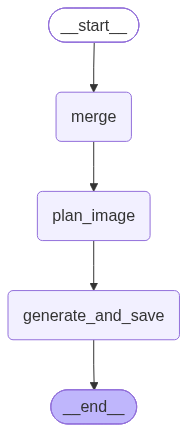

In [12]:
reducer_subgraph

In [21]:
builder = StateGraph(BlogState)

In [22]:
builder.add_node("router", router_node)
builder.add_node("researcher", research_node)
builder.add_node("orchestrator", orchestrator_node)
builder.add_node("worker", worker_node)
builder.add_node("reducer", reducer_subgraph)

In [23]:
builder.add_edge(START, "router")
builder.add_conditional_edges(
    "router", 
    lambda state:'research' if state['needs_research'] else 'orch',
    {
        'research':"researcher",
        'orch':"orchestrator"
    }
)
builder.add_edge("researcher", "orchestrator")
builder.add_conditional_edges("orchestrator", fanout, ['worker'])
builder.add_edge("worker", "reducer")
builder.add_edge("reducer", END)

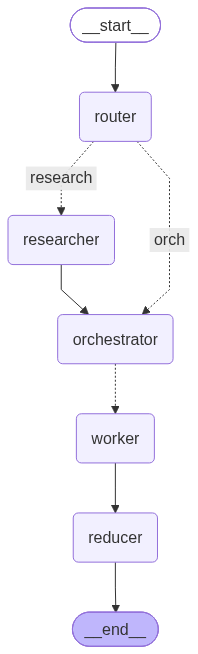

In [24]:
app = builder.compile()
app

In [17]:
# -----------------------------
# 10) Runner
# -----------------------------
def run(topic: str):
    out = app.invoke(
        {
            "topic": topic,
            "mode": "",
            "needs_research": False,
            "queries": [],
            "evidence": [],
            "plan": None,
            "sections": [],
            "final": "",
        }
    )

    return out

In [25]:
run("Recent relases of frontier AI models")

{'topic': 'Recent relases of frontier AI models',
 'mode': 'open_book',
 'needs_research': True,
 'queries': ['List frontier AI models released globally between July 1 2024 and September 30 2024, including model name, organization, architecture, parameter count, and release date.',
  'Identify any major updates or new versions of existing frontier AI models announced from July 2024 to September 2024, with details on improvements and capabilities.',
  'Summarize the key differentiators and benchmark performance (e.g., MMLU, HELM) of the newly released frontier AI models in the July‑September 2024 timeframe.'],
 'evidence': [EvidenceItem(title='Advances at the LLM Frontier – Generative AI for Economic Research', url='https://www.genaiforecon.org/subs/overview.html', published_at=None, snippet='Alibaba\'s Qwen 2.5 (short for Tongyi Qianwen, which translates to "Unified Thousand Questions") has made rapid progress and reached a spot in Table 1 in Sept 2024, even though Alibaba, being locat